In [ ]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from matplotlib import pyplot as plt
import numpy as np
from sklearn.cluster import MiniBatchKMeans
from sklearn.datasets import fetch_openml
from sklearn.metrics import silhouette_score, silhouette_samples
from matplotlib.ticker import FixedFormatter, FixedLocator

In [81]:
#Centroides dos clustres 
blob_centers = np.array([[ 0.2,  2.3], [-1.5 ,  2.3], [-2.8,  1.8],[-2.8,  2.8], [-2.8,  1.3]])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])
X, y = make_blobs(n_samples=2000, centers=blob_centers, cluster_std=blob_std,
                  random_state=0)

k = 5
kmeans = KMeans(n_clusters=5, random_state=42)
y_pred = kmeans.fit_predict(X)


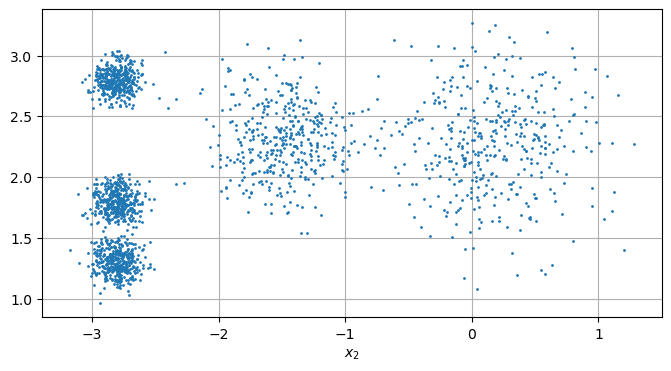

In [82]:
def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$")
    plt.xlabel("$x_2$", rotation=0)

plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.gca().set_axisbelow(True)
plt.grid()

plt.show()

In [83]:
y_pred

array([0, 4, 4, ..., 0, 0, 3], dtype=int32)

In [84]:
kmeans.labels_

array([0, 4, 4, ..., 0, 0, 3], dtype=int32)

In [85]:
y_pred is kmeans.labels_

True

In [86]:
kmeans.cluster_centers_, blob_centers

(array([[ 0.18071959,  2.27487424],
        [-2.80180006,  2.79464334],
        [-2.80379109,  1.30017997],
        [-1.46126243,  2.31093009],
        [-2.80446936,  1.79959228]]),
 array([[ 0.2,  2.3],
        [-1.5,  2.3],
        [-2.8,  1.8],
        [-2.8,  2.8],
        [-2.8,  1.3]]))

In [87]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1_000, show_centroids=True,
                            show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                            np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
            cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)


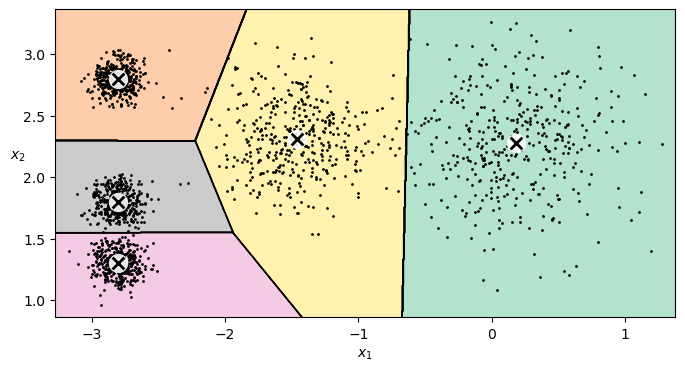

In [88]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)

plt.show()

A inicialização dos `centroids` é aleatória o ponto em que se inicia pode levar a N soluções, a quantidade de iterações `max_inter` também é importante para buscar o valor ótimo dada a inicialização. 

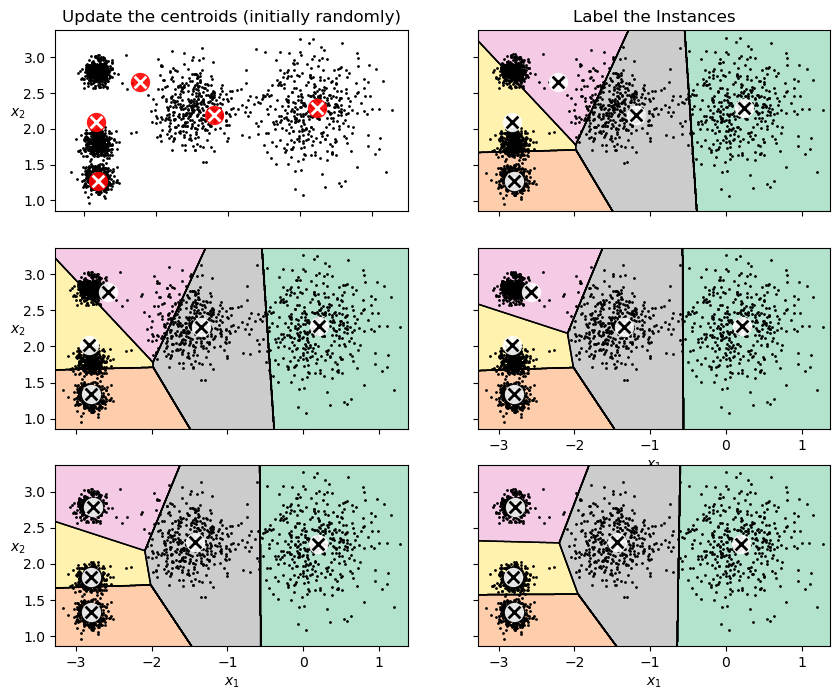

In [94]:
iteracao_1 = KMeans(n_clusters=5, init='random', n_init=1, max_iter=1, random_state=42)
iteracao_2 = KMeans(n_clusters=5, init='random', n_init=1, max_iter=2, random_state=42)
iteracao_3 = KMeans(n_clusters=5, init='random', n_init=1, max_iter=3, random_state=42)

iteracao_1.fit(X)
iteracao_2.fit(X)
iteracao_3.fit(X)

plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(iteracao_1.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Update the centroids (initially randomly)")

plt.subplot(322)
plot_decision_boundaries(iteracao_1, X, show_xlabels=False, show_ylabels=False)
plt.title("Label the Instances")

plt.subplot(323)
plot_decision_boundaries(iteracao_1, X, show_centroids=False, show_xlabels=False)
plot_centroids(iteracao_2.cluster_centers_)

plt.subplot(324)
plot_decision_boundaries(iteracao_2, X, show_ylabels=False)

plt.subplot(325)
plot_decision_boundaries(iteracao_2, X, show_centroids=False)
plot_centroids(iteracao_3.cluster_centers_)

plt.subplot(326)
plot_decision_boundaries(iteracao_3, X, show_ylabels=False)


plt.show()

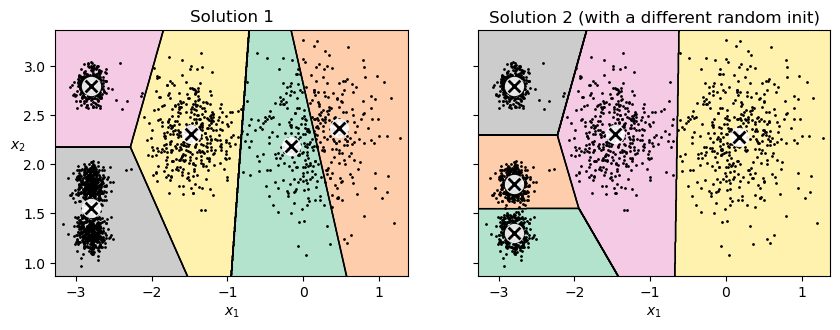

In [95]:
def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None,
                              title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2)

kmeans_rnd_init1 = KMeans(n_clusters=5, init="random", n_init=1, random_state=2)
kmeans_rnd_init2 = KMeans(n_clusters=5, init="random", n_init=1, random_state=8)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,
                          "Solution 1",
                          "Solution 2 (with a different random init)")


plt.show()

Observando os dados em um plot e tendo uma divisão de certa forma visível, também é possicial iniciar os pontos manualmente

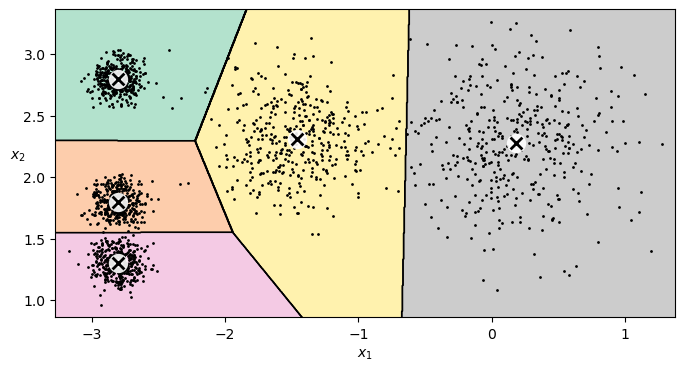

In [96]:
good_init = np.array([[-3, 3], [-3, 2], [-3, 1], [-1, 2], [0, 2]])
kmeans = KMeans(n_clusters=5, init=good_init, random_state=42)
kmeans.fit(X)
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)

**Inércia**

$$ inertia = \sum_{i} \|x^{(i)} - c^i \|^2 $$

Soma das distâncias dos pontos para seu centroide respectivo, podemos usa como um comparativo entre modelos

In [97]:
kmeans.inertia_, kmeans_rnd_init1.inertia_, kmeans_rnd_init2.inertia_

(210.90881543180112, 220.237636727566, 210.9054019146809)

**Inicialização Multipla**

Existe um método de inicialização de centroides otimizado que se chama `k-means++` que faz uma inicialização por probabilidade de distancia entre os pontos para escolher os próximos centroides, com isso pontos que estiverem mais distantes de centroides tem maior probabilidade de terem um centroide em sua posição 

$$ P(x^{i}) = \frac{D(x^{i})^2}{\sum_{j=1}^{m} D(x^{i})^2} $$

Onde:
* $D(x^{i})$ é a distancia entre a instância $x^{i}$ e o centroide mais próximo já escolhido *
* $m$ é o numero total de instâncias no conjunto de dados

Por padrão o `KMeans` do skitlearn já utiliza este método, porém de forma múltipla


**Mini-Batch K-Means**

Para trabalhar com grandes datasets que não cambem na memória existe o MiniBatchKMeans que propricia trabalhar em batchs

In [99]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(n_clusters=5, random_state=42, batch_size=2048)
minibatch_kmeans.fit(X)
minibatch_kmeans.inertia_

210.9380115542219

**Mini-Batch com memmap**

O `memmap` cria um array que acessa dados diretamente de um arquivo no disco, permitindo trabalhar com arquivos muito grandes sem carregá-los totalmente na memória RAM

A seguir será feito com os dados do mnist a implementação

In [ ]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)
X_train, y_train = mnist.data[:60000], mnist.target[:60000]
X_test, y_test = mnist.data[60000:], mnist.target[60000:]

In [101]:
filename = "my_mnist.mmap"
X_memmap = np.memmap(filename, dtype='float32', mode='write',
                     shape=X_train.shape)
X_memmap[:] = X_train
X_memmap.flush()

In [105]:
X_memmap.shape, X_train.shape

((60000, 784), (60000, 784))

In [106]:
minibatch_kmeans = MiniBatchKMeans(n_clusters=10, batch_size=10,
                                   random_state=42)
minibatch_kmeans.fit(X_memmap)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1952: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=1
  warnings.warn(


MiniBatchKMeans(batch_size=10, n_clusters=10, random_state=42)

**Encontrar a quantidade ótima de clusters**

O grande desafio de clusterização é encontrar a quantidade ideal de clusters, conhecemos a medida de inércia que até podemos usar para identificar o número ótimo de clusters, porém pois quanto maior a quantidade de clusters menor será o valor de inércia, existe outra medida que é a silhueta que nos permite escolher de forma mais fundamentada 

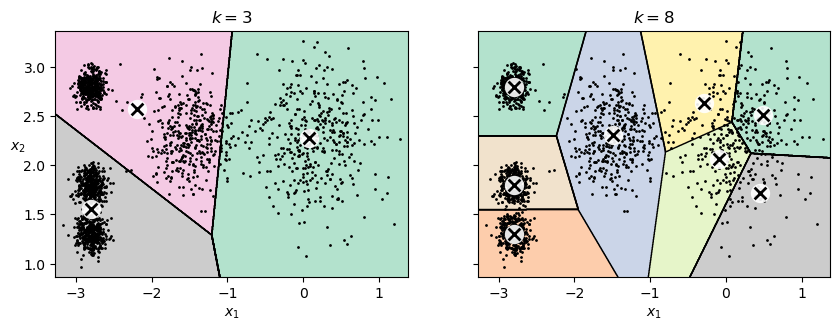

In [107]:
kmeans_k3 = KMeans(n_clusters=3, random_state=42)
kmeans_k8 = KMeans(n_clusters=8, random_state=42)

plot_clusterer_comparison(kmeans_k3, kmeans_k8, X, "$k=3$", "$k=8$")

plt.show()

In [ ]:
# Problema de pensar em escolher o menor valor sempre
kmeans_k3.inertia_, kmeans_k8.inertia_

(646.2302690556882, 129.52493709312262)

Plot de inércia pela função de K(clusters).

Esse plot nos mostra quando o incremento de número de clusters começa a não fazer mais tanta diferença, mas sabemos que o problema/dataset foi feito com 5 clusters, então escolher por inércia nem sempre será uma boa solução

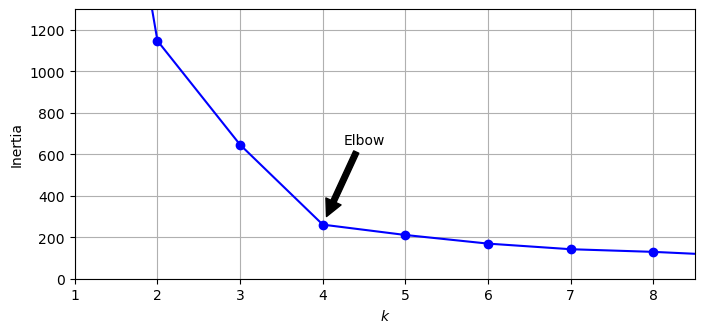

In [125]:
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("", xy=(4, inertias[3]), xytext=(4.45, 650),
             arrowprops=dict(facecolor='black', shrink=0.1))
plt.text(4.5, 650, "Elbow", horizontalalignment="center")
plt.axis([1, 8.5, 0, 1300])
plt.grid()

plt.show()

In [126]:
from sklearn.metrics import silhouette_score
silhouette_score(X, kmeans.labels_)

np.float64(0.6553151762115746)

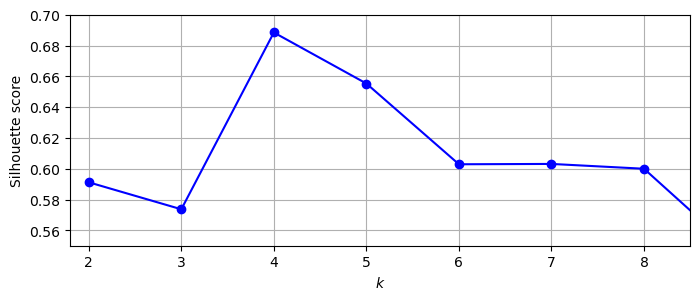

In [127]:
silhouette_scores = [silhouette_score(X, model.labels_)
                     for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.grid()

A quantidade 4 de clusters ainda se apresenta como a melhor, porém a quantidade 5 é melhor representada e conseguimos notar que os valores acima dele perdem bastante desempenho. 

O gráfico a seguir (*silhouette diagram*) nos mostra o balanceamento, distância e desidade dos clusters, nesse caso identificaremos que com a quantidade de k=4 uma `lámina` fica bem maior, indicando um desbalanceamento

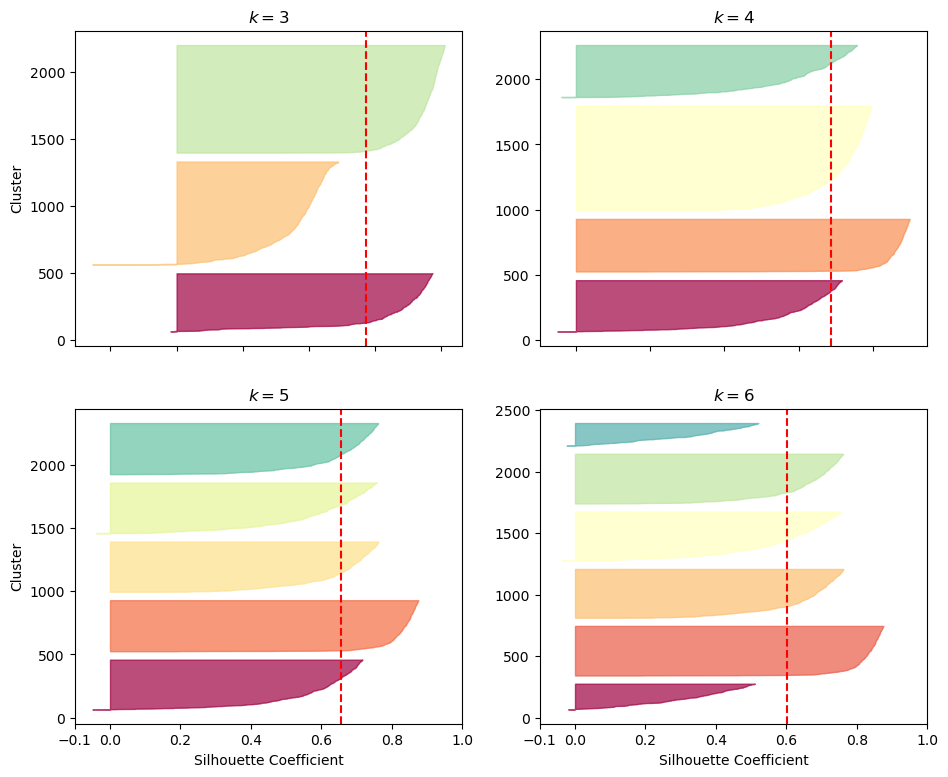

In [128]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedFormatter, FixedLocator

plt.figure(figsize=(11, 9))

for k in (3,4,5,6):
    plt.subplot(2,2, k-2)
    
    y_pred = kmeans_per_k[k-1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X)//30
    pos = padding
    ticks = []

    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = plt.cm.Spectral(i/k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)),0,coeffs,facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos+len(coeffs)//2)
        pos += len(coeffs) + padding

    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (5,6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel('Silhouette Coefficient')
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color='red', linestyle='--')
    plt.title(f"$k={k}$")

plt.show()
